## Chủ đề số 14: Bank marketing
## Bài toán: Dự đoán khách hàng có đăng ký gửi tiền kỳ hạn hay không (Yes/No)
## Loại bài toán: Classification

### Tập dữ liệu: UCI Bank Marketing (https://archive.ics.uci.edu/dataset/222/bank+marketing)
### Thuật toán trong notebook: K-Nearest Neighbors (KNN)
### Độ đo: F1, Recall, ROC-AUC

### 1. Giới thiệu bài toán và dữ liệu

#### 1.1. Bài toán

- **Bối cảnh:** dữ liệu ghi lại các cuộc gọi marketing trực tiếp của một ngân hàng nhằm mời khách hàng gửi tiền kỳ hạn.
- **Mục tiêu:** dự đoán khách hàng có đăng ký tiền gửi kỳ hạn hay không, giúp ngân hàng ưu tiên liên hệ nhóm khách tiềm năng và giảm chi phí cuộc gọi.
- **Input:** thông tin khách hàng và chiến dịch marketing.
- **Output:** `yes` (đăng ký) hoặc `no` (không đăng ký).
- **Loại bài toán:** học có giám sát, phân loại nhị phân (Classification).

#### 1.2. Dữ liệu

Nguồn: UCI Bank Marketing, tệp `bank-additional-full.csv`. Notebook sử dụng các tập train/test và nhãn đã được chuẩn bị ở notebook EDA và tiền xử lý dùng chung; không thực hiện lại EDA hoặc tiền xử lý tại đây.

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Tìm thư mục dự án từ vị trí notebook hoặc thư mục chạy hiện tại.
ROOT_DIR = next(
    (p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (p / "src" / "config.py").exists()),
    None,
)
if ROOT_DIR is None:
    raise FileNotFoundError("Không tìm thấy thư mục dự án chứa src/config.py.")

PROCESSED_DATA_DIR = ROOT_DIR / "data" / "processed"
required_files = ["X_train.csv", "X_test.csv", "y_train.csv", "y_test.csv"]
missing_files = [name for name in required_files if not (PROCESSED_DATA_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(
        f"Thiếu dữ liệu đã tiền xử lý trong {PROCESSED_DATA_DIR}: {missing_files}. "
        "Chạy notebook EDA và tiền xử lý dùng chung trước."
    )

X_train_df = pd.read_csv(PROCESSED_DATA_DIR / "X_train.csv")
X_test_df = pd.read_csv(PROCESSED_DATA_DIR / "X_test.csv")
y_train = pd.read_csv(PROCESSED_DATA_DIR / "y_train.csv").squeeze("columns")
y_test = pd.read_csv(PROCESSED_DATA_DIR / "y_test.csv").squeeze("columns")
X_train = X_train_df.to_numpy()
X_test = X_test_df.to_numpy()
feature_names = X_train_df.columns.to_numpy()
N_FOLDS = 5
RESULTS_DIR = ROOT_DIR / "notebooks" / "02_EDA" / "Experiments" / "Logs"

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print("Số fold dùng cho cross-validation:", N_FOLDS)

Train: (32940, 62), Test: (8236, 62)
Số fold dùng cho cross-validation: 5


In [2]:
import os
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)

def knn_metrics(y_true, y_pred, y_proba):
    """Tính các độ đo với lớp yes = 1 là lớp dương."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
    }

def save_experiment(exp_name, model, params, y_true, y_pred, y_proba):
    """Lưu cấu hình, độ đo, dự đoán, mô hình và biểu đồ cho một thí nghiệm."""
    folder = RESULTS_DIR / exp_name
    folder.mkdir(parents=True, exist_ok=True)
    metrics = knn_metrics(y_true, y_pred, y_proba)

    with (folder / "params_cfg.json").open("w", encoding="utf-8") as file:
        json.dump(params, file, ensure_ascii=False, indent=2, default=str)
    with (folder / "metrics.json").open("w", encoding="utf-8") as file:
        json.dump(metrics, file, ensure_ascii=False, indent=2)
    pd.DataFrame([metrics]).round(4).to_csv(folder / "metrics.csv", index=False)
    pd.DataFrame({
        "y_true": np.asarray(y_true),
        "y_pred": np.asarray(y_pred),
        "y_proba": np.asarray(y_proba),
    }).to_csv(folder / "predictions.csv", index=False)
    joblib.dump(model, folder / "best_model.pkl")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, labels=[0, 1], display_labels=["No", "Yes"],
        cmap="Blues", ax=axes[0]
    )
    axes[0].set_title(f"{exp_name} - Confusion Matrix")
    RocCurveDisplay.from_predictions(y_true, y_proba, ax=axes[1])
    axes[1].plot([0, 1], [0, 1], "k--")
    axes[1].set_title(f"{exp_name} - ROC Curve")
    fig.tight_layout()
    fig.savefig(folder / "confusion_roc.png", dpi=150)
    plt.close(fig)
    print("Đã lưu vào:", folder)
    return metrics

if "all_results" not in globals():
    all_results = []
if "all_probas" not in globals():
    all_probas = {}

def knn_save_result(name, metrics, proba):
    """Cập nhật kết quả chung, tránh tạo dòng trùng khi chạy lại cell."""
    all_results[:] = [row for row in all_results if row["Model"] != name]
    all_results.append({"Model": name, **metrics})
    all_probas[name] = np.asarray(proba)

def knn_report(name, y_true, y_pred, y_proba):
    """In báo cáo, vẽ biểu đồ và cập nhật kết quả của một phiên bản KNN."""
    from sklearn.metrics import classification_report

    metrics = knn_metrics(y_true, y_pred, y_proba)
    print(f"===== {name.upper()} =====")
    for metric, value in metrics.items():
        print(f"{metric:<10}: {value:.4f}")
    print("\n===== CLASSIFICATION REPORT =====")
    print(classification_report(
        y_true, y_pred, labels=[0, 1], target_names=["No", "Yes"], zero_division=0
    ))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, labels=[0, 1], display_labels=["No", "Yes"],
        cmap="Blues", ax=axes[0]
    )
    axes[0].set_title(f"{name} - Confusion Matrix")
    RocCurveDisplay.from_predictions(y_true, y_proba, name=name, ax=axes[1])
    axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
    axes[1].set_title(f"{name} - ROC Curve")
    axes[1].legend(loc="lower right")
    fig.tight_layout()
    plt.show()

    knn_save_result(name, metrics, y_proba)
    return metrics

### 7. Thuật toán K-Nearest Neighbors (KNN)

#### 7.1. Giới thiệu thuật toán

K-Nearest Neighbors (KNN) là thuật toán học có giám sát dùng cho phân loại và hồi quy. Với bài toán Bank Marketing, KNN dự đoán khách hàng có đăng ký tiền gửi hay không dựa trên nhãn của K khách hàng gần nhất trong không gian đặc trưng.

- **Ưu điểm:** dễ hiểu, không giả định dạng phân phối của dữ liệu.
- **Nhược điểm:** dự đoán chậm khi dữ liệu lớn, nhạy với thang đo đặc trưng và mất cân bằng lớp.

Dữ liệu đầu vào đã được chuẩn hóa và mã hóa ở notebook tiền xử lý dùng chung. Cấu hình baseline: `K=5`, khoảng cách Euclidean, biểu quyết đều (`weights="uniform"`).

#### 7.2. Huấn luyện và dự đoán

Huấn luyện KNN lưu lại các mẫu train; việc tìm láng giềng diễn ra khi dự đoán. Dự đoán nhãn (0: không đăng ký, 1: đăng ký) và xác suất đăng ký trên tập test.

In [3]:
from sklearn.neighbors import KNeighborsClassifier

model_knn = KNeighborsClassifier(
    n_neighbors=5,
    weights="uniform",
    metric="euclidean",
    n_jobs=-1,
)
model_knn.fit(X_train, y_train)
y_pred_knn = model_knn.predict(X_test)
y_proba_knn = model_knn.predict_proba(X_test)[:, 1]

print("Huấn luyện và dự đoán KNN hoàn tất!")
print("10 nhãn dự đoán đầu tiên:", y_pred_knn[:10])
print("10 xác suất dự đoán đầu tiên:", y_proba_knn[:10].round(4))

Huấn luyện và dự đoán KNN hoàn tất!
10 nhãn dự đoán đầu tiên: [0 1 0 0 0 0 0 0 0 0]
10 xác suất dự đoán đầu tiên: [0.  0.6 0.2 0.2 0.2 0.  0.  0.  0.  0.2]


#### 7.3. Đánh giá mô hình

Đánh giá trên tập test bằng F1-score, Recall, ROC-AUC; bổ sung Accuracy và Precision. Do dữ liệu mất cân bằng nên ưu tiên F1-score và Recall hơn Accuracy.

In [4]:
from sklearn.metrics import classification_report

metrics_knn_baseline = knn_metrics(y_test, y_pred_knn, y_proba_knn)
print("===== KNN BASELINE =====")
for metric, value in metrics_knn_baseline.items():
    print(f"{metric:<10}: {value:.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test, y_pred_knn, labels=[0, 1], target_names=["No", "Yes"], zero_division=0
))

===== KNN BASELINE =====
Accuracy  : 0.8955
Precision : 0.5661
Recall    : 0.3093
F1-score  : 0.4000
ROC-AUC   : 0.7404

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.92      0.97      0.94      7308
         Yes       0.57      0.31      0.40       928

    accuracy                           0.90      8236
   macro avg       0.74      0.64      0.67      8236
weighted avg       0.88      0.90      0.88      8236



#### 7.4. Trực quan hóa kết quả

Confusion Matrix cho biết số khách hàng dự đoán đúng/sai ở từng lớp, đặc biệt là số khách đăng ký bị bỏ sót (False Negative). ROC Curve thể hiện khả năng phân biệt hai lớp ở nhiều ngưỡng.

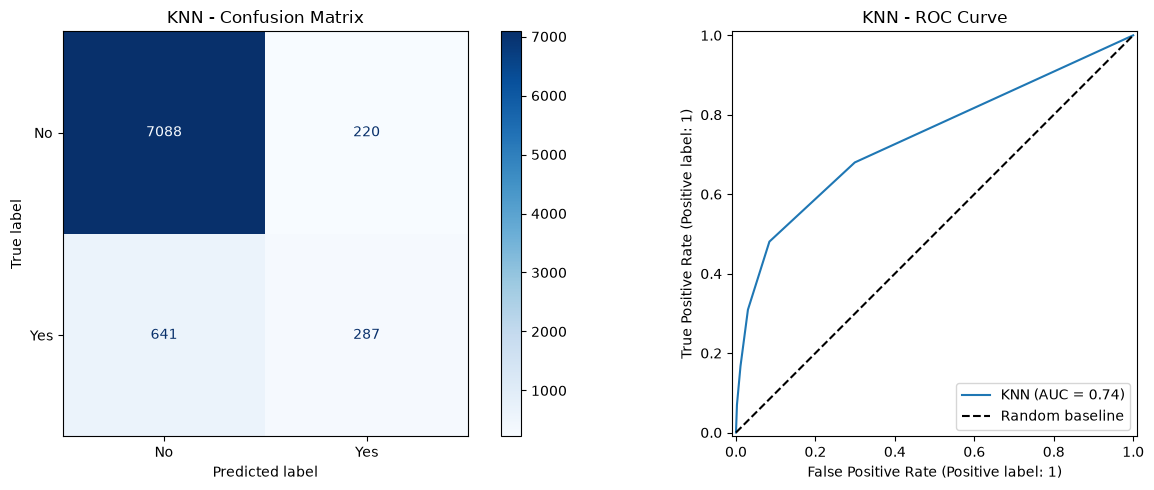

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_knn, labels=[0, 1], display_labels=["No", "Yes"],
    cmap="Blues", ax=axes[0]
)
axes[0].set_title("KNN - Confusion Matrix")
RocCurveDisplay.from_predictions(y_test, y_proba_knn, name="KNN", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
axes[1].set_title("KNN - ROC Curve")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

#### 7.5. Nhận xét

Ghi nhận F1-score, Recall và ROC-AUC theo kết quả chạy. KNN có bỏ sót nhiều khách đăng ký không? Kết quả có cho thấy cần thử SMOTE hoặc điều chỉnh ngưỡng?

In [6]:
knn_save_result("KNN (baseline)", metrics_knn_baseline, y_proba_knn)
metrics_knn_baseline_saved = save_experiment(
    "Experiment_02_KNN_baseline",
    model_knn,
    model_knn.get_params(),
    y_test,
    y_pred_knn,
    y_proba_knn,
)
print("Đã lưu kết quả KNN baseline.")

Đã lưu vào: /workspaces/MayHoc_Nhom/Đồ án cuối kỳ/notebooks/02_EDA/Experiments/Logs/Experiment_02_KNN_baseline
Đã lưu kết quả KNN baseline.


### 9. Xử lý mất cân bằng lớp và chỉnh ngưỡng

#### 9.2. KNN

##### 9.2.1. Cân bằng dữ liệu bằng SMOTE

SMOTE chỉ được áp dụng trên tập train; tập test giữ nguyên để đánh giá trên phân bố thực tế. Với dữ liệu One-Hot, các mẫu tổng hợp có thể nhận giá trị phân số ở cột mã hóa.

Đang huấn luyện KNN + SMOTE...
===== KNN (SMOTE) =====
Accuracy  : 0.7390
Precision : 0.2448
Recall    : 0.6315
F1-score  : 0.3528
ROC-AUC   : 0.7315

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.94      0.75      0.84      7308
         Yes       0.24      0.63      0.35       928

    accuracy                           0.74      8236
   macro avg       0.59      0.69      0.59      8236
weighted avg       0.86      0.74      0.78      8236



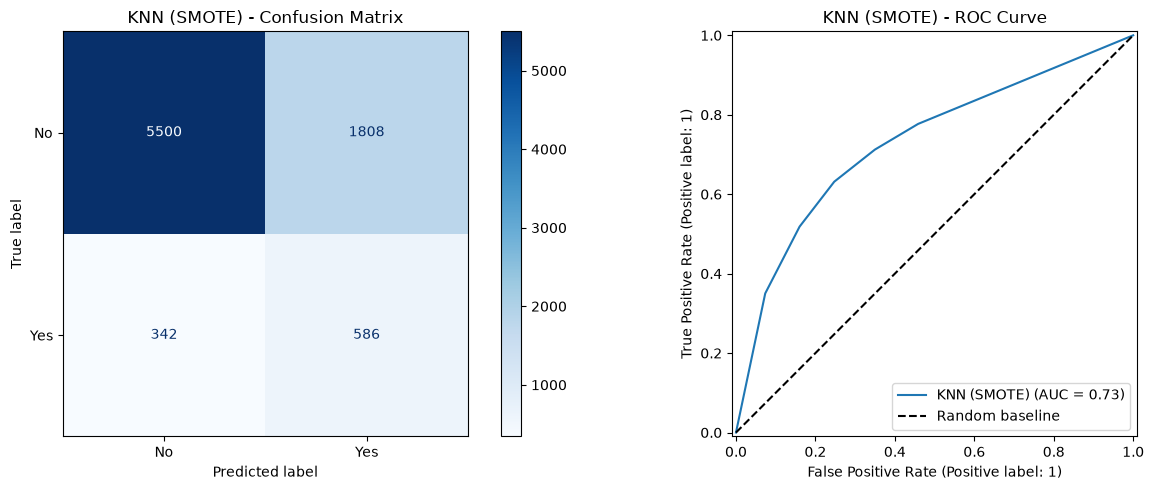

Đã lưu vào: /workspaces/MayHoc_Nhom/Đồ án cuối kỳ/notebooks/02_EDA/Experiments/Logs/Experiment_06_KNN_SMOTE


{'Accuracy': 0.7389509470616804,
 'Precision': 0.24477861319966582,
 'Recall': 0.6314655172413793,
 'F1-score': 0.3527995183624323,
 'ROC-AUC': 0.7314792451116394}

In [7]:
from imblearn.over_sampling import SMOTE

print("Đang huấn luyện KNN + SMOTE...", flush=True)
X_knn_smote, y_knn_smote = SMOTE(random_state=42).fit_resample(X_train, y_train)
model_knn_smote = KNeighborsClassifier(
    n_neighbors=5, weights="uniform", metric="euclidean", n_jobs=-1
)
model_knn_smote.fit(X_knn_smote, y_knn_smote)
y_pred_knn_smote = model_knn_smote.predict(X_test)
y_proba_knn_smote = model_knn_smote.predict_proba(X_test)[:, 1]
metrics_knn_smote = knn_report(
    "KNN (SMOTE)", y_test, y_pred_knn_smote, y_proba_knn_smote
)
save_experiment(
    "Experiment_06_KNN_SMOTE", model_knn_smote,
    {"n_neighbors": 5, "weights": "uniform", "metric": "euclidean", "sampling": "SMOTE", "random_state": 42},
    y_test, y_pred_knn_smote, y_proba_knn_smote,
)

##### 9.2.2. Chỉnh ngưỡng phân loại

Chọn ngưỡng bằng dự đoán out-of-fold trên tập train, tối ưu F1-score. Không dùng tập test để chọn ngưỡng.

,Threshold,Precision,Recall,F1-score
2,0.4,0.3961,0.4487,0.4208
3,0.6,0.5333,0.2935,0.3786
1,0.2,0.2175,0.6597,0.3271
4,0.8,0.6398,0.1560,0.2509
0,0.0,0.1127,1.0000,0.2025
5,1.0,0.7083,0.0504,0.0941


Ngưỡng được chọn trên train: 0.4000
F1-score OOF tại ngưỡng này: 0.4208


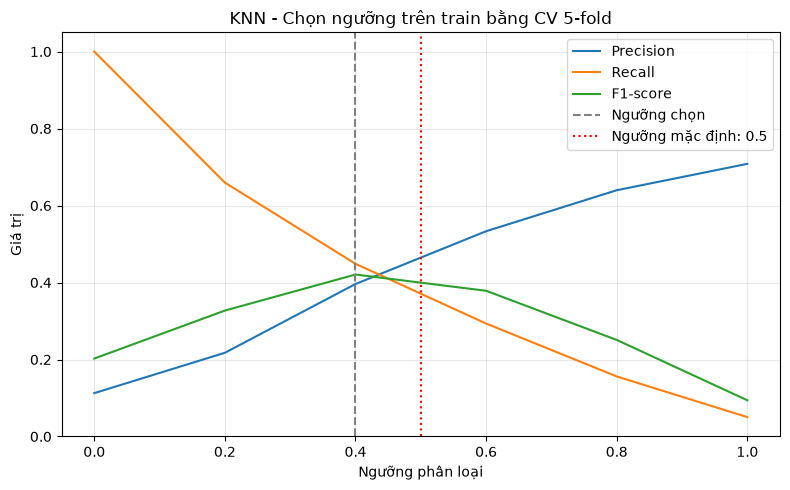

===== KNN (THRESHOLD) =====
Accuracy  : 0.8668
Precision : 0.4204
Recall    : 0.4806
F1-score  : 0.4485
ROC-AUC   : 0.7404

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.93      0.92      0.92      7308
         Yes       0.42      0.48      0.45       928

    accuracy                           0.87      8236
   macro avg       0.68      0.70      0.69      8236
weighted avg       0.88      0.87      0.87      8236



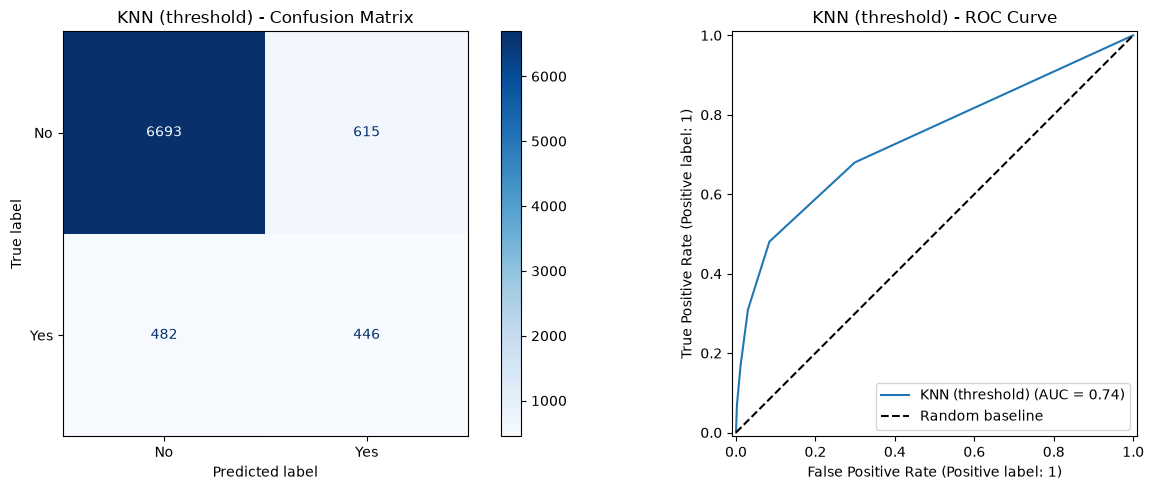

Đã lưu vào: /workspaces/MayHoc_Nhom/Đồ án cuối kỳ/notebooks/02_EDA/Experiments/Logs/Experiment_KNN_threshold


{'Accuracy': 0.8668042739193783,
 'Precision': 0.4203581526861451,
 'Recall': 0.48060344827586204,
 'F1-score': 0.44846656611362495,
 'ROC-AUC': 0.7404146731026934}

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_recall_curve

cv_knn_threshold = StratifiedKFold(
    n_splits=N_FOLDS, shuffle=True, random_state=42
)
oof_proba_knn = cross_val_predict(
    KNeighborsClassifier(
        n_neighbors=5, weights="uniform", metric="euclidean", n_jobs=1
    ),
    X_train,
    y_train,
    cv=cv_knn_threshold,
    method="predict_proba",
    n_jobs=2,
)[:, 1]

precision_oof, recall_oof, thresholds_knn = precision_recall_curve(y_train, oof_proba_knn)
f1_oof = np.divide(
    2 * precision_oof[:-1] * recall_oof[:-1],
    precision_oof[:-1] + recall_oof[:-1],
    out=np.zeros_like(precision_oof[:-1]),
    where=(precision_oof[:-1] + recall_oof[:-1]) > 0,
)
df_thr_knn = pd.DataFrame({
    "Threshold": thresholds_knn,
    "Precision": precision_oof[:-1],
    "Recall": recall_oof[:-1],
    "F1-score": f1_oof,
})
best_idx_knn = df_thr_knn["F1-score"].idxmax()
best_threshold_knn = float(df_thr_knn.loc[best_idx_knn, "Threshold"])

display(df_thr_knn.round(4).sort_values("F1-score", ascending=False).head(10))
print(f"Ngưỡng được chọn trên train: {best_threshold_knn:.4f}")
print(f"F1-score OOF tại ngưỡng này: {f1_oof[best_idx_knn]:.4f}")

plt.figure(figsize=(8, 5))
for metric in ["Precision", "Recall", "F1-score"]:
    plt.plot(df_thr_knn["Threshold"], df_thr_knn[metric], label=metric)
plt.axvline(best_threshold_knn, color="gray", linestyle="--", label="Ngưỡng chọn")
plt.axvline(0.5, color="red", linestyle=":", label="Ngưỡng mặc định: 0.5")
plt.title(f"KNN - Chọn ngưỡng trên train bằng CV {N_FOLDS}-fold")
plt.xlabel("Ngưỡng phân loại")
plt.ylabel("Giá trị")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

y_pred_knn_thr = (y_proba_knn >= best_threshold_knn).astype(int)
metrics_knn_thr = knn_report(
    "KNN (threshold)", y_test, y_pred_knn_thr, y_proba_knn
)
save_experiment(
    "Experiment_KNN_threshold", model_knn,
    {"n_neighbors": 5, "weights": "uniform", "metric": "euclidean", "threshold": best_threshold_knn},
    y_test, y_pred_knn_thr, y_proba_knn,
)

##### 9.2.3. Nhận xét

So sánh baseline, SMOTE và chỉnh ngưỡng theo Precision, Recall, F1-score và ROC-AUC. Việc tăng Recall có làm giảm Precision không? Cân nhắc chi phí bỏ sót khách hàng tiềm năng so với chi phí gọi nhầm.

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
KNN (baseline),0.8955,0.5661,0.3093,0.4000,0.7404
KNN (SMOTE),0.7390,0.2448,0.6315,0.3528,0.7315
KNN (threshold),0.8668,0.4204,0.4806,0.4485,0.7404


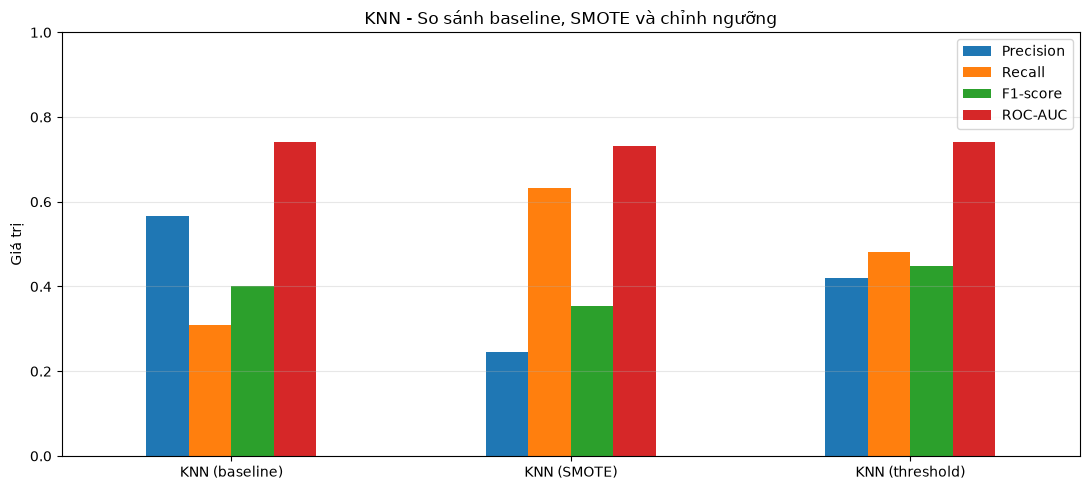

In [9]:
df_knn_section9 = pd.DataFrame([
    {"Model": "KNN (baseline)", **metrics_knn_baseline},
    {"Model": "KNN (SMOTE)", **metrics_knn_smote},
    {"Model": "KNN (threshold)", **metrics_knn_thr},
]).set_index("Model")
display(df_knn_section9.round(4))
df_knn_section9[["Precision", "Recall", "F1-score", "ROC-AUC"]].plot(
    kind="bar", figsize=(11, 5), ylim=(0, 1), rot=0
)
plt.title("KNN - So sánh baseline, SMOTE và chỉnh ngưỡng")
plt.xlabel("")
plt.ylabel("Giá trị")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 10. Tinh chỉnh siêu tham số

#### 10.2. KNN

##### 10.2.1. Tìm kiếm siêu tham số

Dùng GridSearchCV trên train với Stratified 3-fold, tối ưu F1-score và theo dõi Recall, ROC-AUC. Khảo sát `n_neighbors` = 5, 11, 21 và `weights` = `uniform`, `distance`; khoảng cách Euclidean (`p=2`).

In [10]:
import time
from sklearn.model_selection import GridSearchCV

param_grid_knn = {
    "n_neighbors": [5, 11, 21],
    "weights": ["uniform", "distance"],
    "p": [2],
}
cv_knn_tuning = StratifiedKFold(
    n_splits=N_FOLDS, shuffle=True, random_state=42
)
search_knn = GridSearchCV(
    estimator=KNeighborsClassifier(metric="minkowski", n_jobs=1),
    param_grid=param_grid_knn,
    scoring={"f1": "f1", "recall": "recall", "roc_auc": "roc_auc"},
    refit="f1",
    cv=cv_knn_tuning,
    n_jobs=2,
    pre_dispatch=2,
    verbose=1,
    error_score="raise",
)
start_knn = time.perf_counter()
search_knn.fit(X_train, y_train)
elapsed_knn = time.perf_counter() - start_knn
print(f"Thời gian tìm kiếm: {elapsed_knn / 60:.2f} phút")
print("Tham số tốt nhất:", search_knn.best_params_)
print(f"F1-score CV tốt nhất: {search_knn.best_score_:.4f}")

cv_results_knn = pd.DataFrame(search_knn.cv_results_)
cols_knn = [
    "rank_test_f1", "mean_test_f1", "std_test_f1",
    "mean_test_recall", "mean_test_roc_auc", "params",
]
display(
    cv_results_knn.sort_values("rank_test_f1")[cols_knn]
    .head(10).reset_index(drop=True).round(4)
)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Thời gian tìm kiếm: 0.98 phút
Tham số tốt nhất: {'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}
F1-score CV tốt nhất: 0.3783


,rank_test_f1,mean_test_f1,std_test_f1,mean_test_recall,mean_test_roc_auc,params
0,1,0.3783,0.0140,0.2935,0.7246,"{'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}"
1,2,0.3714,0.0149,0.3015,0.7212,"{'n_neighbors': 5, 'p': 2, 'weights': 'distance'}"
2,3,0.3655,0.0136,0.2770,0.7458,"{'n_neighbors': 11, 'p': 2, 'weights': 'distan..."
3,4,0.3623,0.0112,0.2633,0.7514,"{'n_neighbors': 11, 'p': 2, 'weights': 'uniform'}"
4,5,0.3588,0.0105,0.2619,0.7584,"{'n_neighbors': 21, 'p': 2, 'weights': 'distan..."
5,6,0.3549,0.0069,0.2487,0.7659,"{'n_neighbors': 21, 'p': 2, 'weights': 'uniform'}"


##### 10.2.2. Đánh giá mô hình sau tinh chỉnh

Mô hình tốt nhất đã được GridSearchCV huấn luyện lại trên toàn bộ tập train. Dùng mô hình này để dự đoán tập test và so sánh với các phiên bản trước.

===== KNN (TUNED) =====
Accuracy  : 0.8955
Precision : 0.5661
Recall    : 0.3093
F1-score  : 0.4000
ROC-AUC   : 0.7404

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.92      0.97      0.94      7308
         Yes       0.57      0.31      0.40       928

    accuracy                           0.90      8236
   macro avg       0.74      0.64      0.67      8236
weighted avg       0.88      0.90      0.88      8236



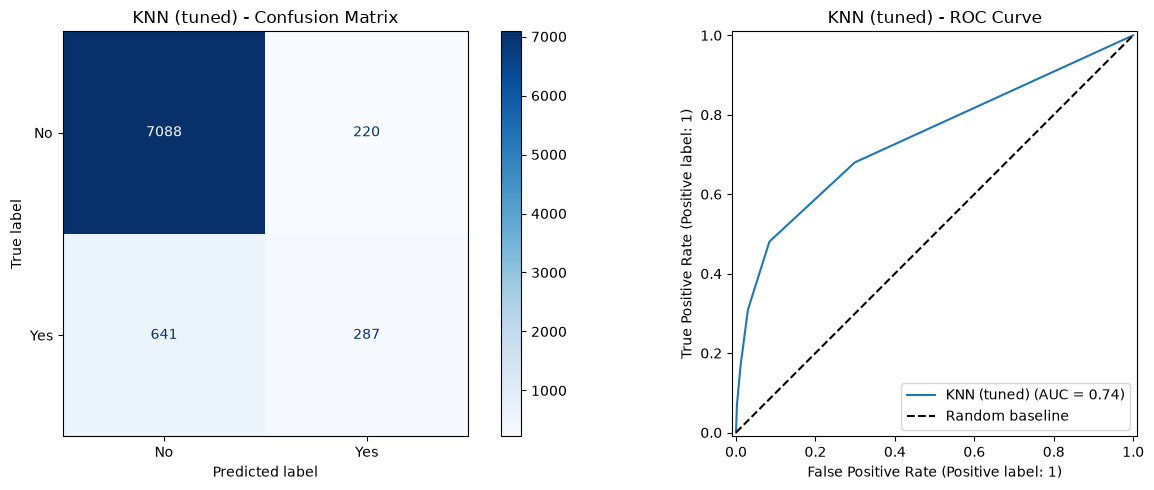

Đã lưu vào: /workspaces/MayHoc_Nhom/Đồ án cuối kỳ/notebooks/02_EDA/Experiments/Logs/Experiment_KNN_tuned
Tham số KNN tốt nhất:
{'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}
Chênh lệch so với baseline:
Accuracy  : +0.0000
Precision : +0.0000
Recall    : +0.0000
F1-score  : +0.0000
ROC-AUC   : +0.0000


In [11]:
model_knn_tuned = search_knn.best_estimator_
y_pred_knn_tuned = model_knn_tuned.predict(X_test)
y_proba_knn_tuned = model_knn_tuned.predict_proba(X_test)[:, 1]
metrics_knn_tuned = knn_report(
    "KNN (tuned)", y_test, y_pred_knn_tuned, y_proba_knn_tuned
)
save_experiment(
    "Experiment_KNN_tuned", model_knn_tuned, search_knn.best_params_,
    y_test, y_pred_knn_tuned, y_proba_knn_tuned,
)

print("Tham số KNN tốt nhất:")
print(search_knn.best_params_)
print("Chênh lệch so với baseline:")
for metric in metrics_knn_baseline:
    difference = metrics_knn_tuned[metric] - metrics_knn_baseline[metric]
    print(f"{metric:<10}: {difference:+.4f}")

##### 10.2.3. Nhận xét

Ghi nhận các tham số tốt nhất và so sánh F1-score, Recall, ROC-AUC với baseline. Tham số `n_neighbors` và cách gán trọng số láng giềng có ảnh hưởng như thế nào đến khả năng nhận diện lớp `yes`?

### 11. So sánh trước và sau tinh chỉnh

Tổng hợp bốn phiên bản KNN: baseline, SMOTE, threshold tuning và hyperparameter tuning. Các kết quả test chỉ dùng để báo cáo; lựa chọn ngưỡng và siêu tham số dựa trên train/CV.

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
KNN (baseline),0.8955,0.5661,0.3093,0.4000,0.7404
KNN (SMOTE),0.7390,0.2448,0.6315,0.3528,0.7315
KNN (threshold),0.8668,0.4204,0.4806,0.4485,0.7404
KNN (tuned),0.8955,0.5661,0.3093,0.4000,0.7404


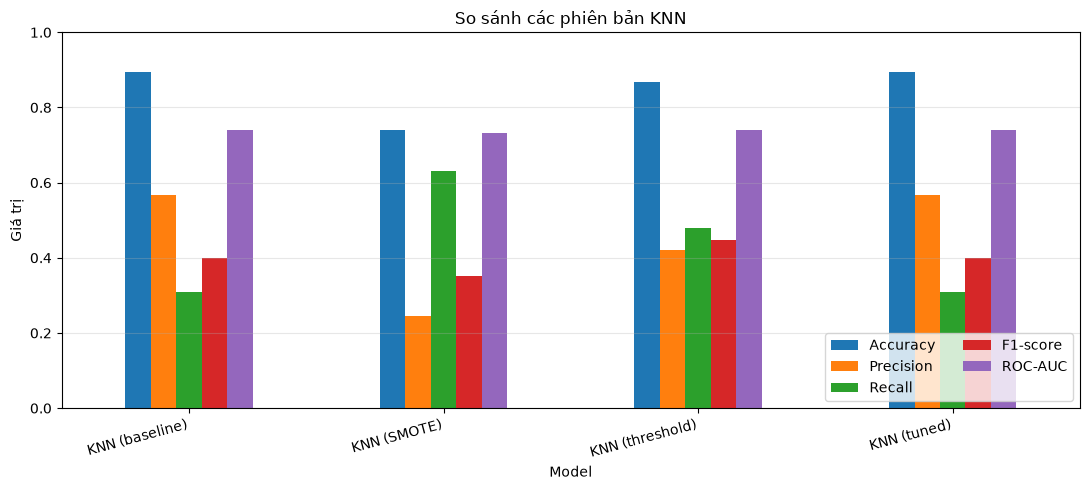

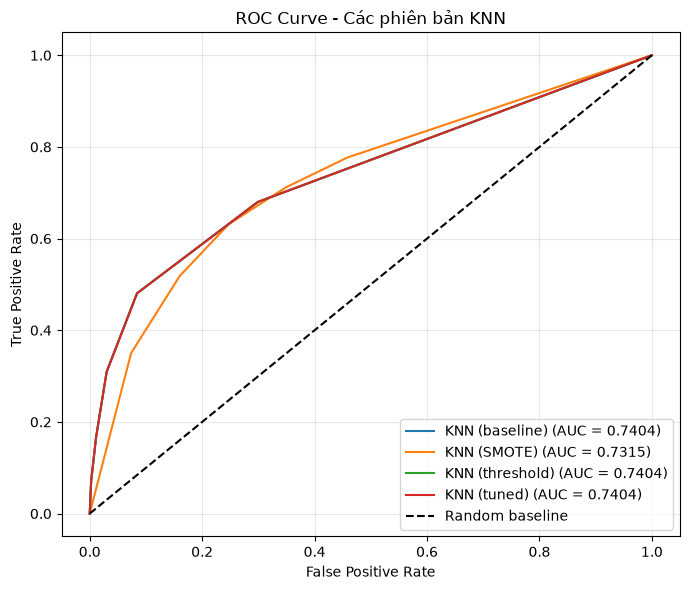

In [12]:
df_knn_compare = pd.DataFrame([
    {"Model": "KNN (baseline)", **metrics_knn_baseline},
    {"Model": "KNN (SMOTE)", **metrics_knn_smote},
    {"Model": "KNN (threshold)", **metrics_knn_thr},
    {"Model": "KNN (tuned)", **metrics_knn_tuned},
]).set_index("Model")
display(df_knn_compare.round(4))

ax = df_knn_compare[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]].plot(
    kind="bar", figsize=(11, 5)
)
ax.set_title("So sánh các phiên bản KNN")
ax.set_ylabel("Giá trị")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right", ncol=2)
plt.tight_layout()
plt.show()

from sklearn.metrics import roc_curve
plt.figure(figsize=(7, 6))
for name, proba in all_probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_value = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_value:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Random baseline")
plt.title("ROC Curve - Các phiên bản KNN")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 12. Phân tích mô hình

#### 12.1. Phân tích các láng giềng gần nhất

KNN không có `feature_importances_` như Random Forest. Thay vào đó, xem nhãn và khoảng cách của các láng giềng gần nhất của một mẫu test để minh họa cách KNN đưa ra dự đoán.

In [13]:
from sklearn.neighbors import KNeighborsClassifier

n_neighbors = model_knn_tuned.n_neighbors
sample_idx = 0
neighbor_distances, neighbor_indices = model_knn_tuned.kneighbors(
    X_test[sample_idx:sample_idx + 1], n_neighbors=n_neighbors
)
neighbor_labels = np.asarray(y_train)[neighbor_indices[0]]
df_neighbors = pd.DataFrame({
    "Train_index": neighbor_indices[0],
    "Distance": neighbor_distances[0],
    "Neighbor_label": neighbor_labels,
})
print(f"Nhãn thật: {int(y_test.iloc[sample_idx])}")
print(f"Nhãn dự đoán: {int(y_pred_knn_tuned[sample_idx])}")
print(f"Xác suất lớp yes: {y_proba_knn_tuned[sample_idx]:.4f}")
display(df_neighbors)
print("Tỷ lệ nhãn yes trong láng giềng:", float(np.mean(neighbor_labels == 1)))

Nhãn thật: 0
Nhãn dự đoán: 0
Xác suất lớp yes: 0.0000


,Train_index,Distance,Neighbor_label
0,23603,1.804268,0
1,28039,2.009131,0
2,10277,2.134935,0
3,22932,2.160502,0
4,15823,2.229971,0


Tỷ lệ nhãn yes trong láng giềng: 0.0


#### 12.2. Phân tích lỗi (Error Analysis)

Phân tích các dự đoán sai của mô hình tốt nhất (**KNN Tuned**) trên tập test:
- **False Negative (FN):** khách thực tế đăng ký (`y=1`) nhưng mô hình đoán `0` — bỏ lỡ khách hàng tiềm năng.
- **False Positive (FP):** khách thực tế không đăng ký (`y=0`) nhưng mô hình đoán `1` — tốn chi phí gọi điện không cần thiết.

In [14]:
from sklearn.metrics import confusion_matrix

raw_test_path = PROCESSED_DATA_DIR / "X_test_raw.csv"
if raw_test_path.is_file():
    df_err = pd.read_csv(raw_test_path)
else:
    df_err = pd.DataFrame(X_test, columns=feature_names)
df_err = df_err.reset_index(drop=True)
df_err["y_true"] = np.asarray(y_test)
df_err["y_pred"] = y_pred_knn_tuned
df_err["y_proba"] = y_proba_knn_tuned

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_knn_tuned, labels=[0, 1]).ravel()
print(f"TP (Đoán đúng Yes): {tp} | FN (Bỏ sót Yes): {fn}")
print(f"TN (Đoán đúng No) : {tn} | FP (Gọi nhầm No) : {fp}")
df_err["error_type"] = np.select(
    [
        (df_err["y_true"] == 1) & (df_err["y_pred"] == 1),
        (df_err["y_true"] == 0) & (df_err["y_pred"] == 0),
        (df_err["y_true"] == 0) & (df_err["y_pred"] == 1),
    ],
    ["TP", "TN", "FP"],
    default="FN",
)

num_cols = [
    col for col in ["age", "campaign", "pdays", "previous", "emp.var.rate", "euribor3m", "nr.employed"]
    if col in df_err.columns
]
if num_cols:
    print("\nTrung bình đặc trưng số theo nhóm dự đoán:")
    display(df_err.groupby("error_type")[num_cols + ["y_proba"]].mean().round(3))
print("\n5 False Negative có xác suất lớp yes thấp nhất:")
display(df_err[df_err["error_type"] == "FN"].sort_values("y_proba").head(5))

TP (Đoán đúng Yes): 287 | FN (Bỏ sót Yes): 641
TN (Đoán đúng No) : 7088 | FP (Gọi nhầm No) : 220

Trung bình đặc trưng số theo nhóm dự đoán:


,age,campaign,pdays,previous,emp.var.rate,euribor3m,nr.employed,y_proba
error_type,,,,,,,,
FN,39.412,2.192,950.997,0.257,-0.909,2.560,5124.304,0.157
FP,42.573,1.936,682.855,0.650,-2.264,1.117,5048.599,0.692
TN,39.921,2.683,991.857,0.113,0.345,3.919,5181.058,0.067
TP,42.742,1.732,459.031,1.000,-2.193,0.929,5021.723,0.753



5 False Negative có xác suất lớp yes thấp nhất:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y_true,y_pred,y_proba,error_type
3737,35,unemployed,single,university.degree,no,no,no,cellular,aug,mon,...,nonexistent,1.4,93.444,-36.1,4.965,5228.1,1,0,0.0,FN
3958,29,technician,single,university.degree,no,yes,yes,telephone,jun,fri,...,nonexistent,1.4,94.465,-41.8,4.959,5228.1,1,0,0.0,FN
3967,36,technician,married,professional.course,no,no,no,telephone,may,wed,...,nonexistent,1.1,93.994,-36.4,4.859,5191.0,1,0,0.0,FN
3984,32,student,single,high.school,no,yes,no,cellular,jul,thu,...,nonexistent,1.4,93.918,-42.7,4.962,5228.1,1,0,0.0,FN
4001,46,admin.,divorced,university.degree,no,no,no,telephone,oct,mon,...,nonexistent,-0.1,93.798,-40.4,4.912,5195.8,1,0,0.0,FN


**Nhận xét phân tích lỗi:**

Xem số lượng False Negative và False Positive cùng xác suất dự đoán của chúng. Trong bài toán ngân hàng, FN có thể làm bỏ lỡ khách hàng tiềm năng, còn FP làm phát sinh cuộc gọi không hiệu quả; cân nhắc mục tiêu kinh doanh khi chọn ngưỡng.

### 13. Lưu mô hình

Lưu mô hình KNN đã tinh chỉnh bằng `joblib`, sau đó nạp lại và đối chiếu dự đoán để kiểm tra khả năng tái sử dụng.

In [15]:
model_dir = ROOT_DIR / "notebooks" / "KNN" / "ket_qua_knn"
model_dir.mkdir(parents=True, exist_ok=True)
model_path = model_dir / "knn_tuned.pkl"
joblib.dump(model_knn_tuned, model_path)
print(f"Đã lưu mô hình tốt nhất tại: {model_path}")

loaded_model_knn = joblib.load(model_path)
sample_pred_knn = loaded_model_knn.predict(X_test[:5])
sample_proba_knn = loaded_model_knn.predict_proba(X_test[:5])[:, 1]
if not np.array_equal(sample_pred_knn, y_pred_knn_tuned[:5]):
    raise AssertionError("Dự đoán sau khi nạp lại mô hình không khớp!")
print("Kiểm tra nạp lại thành công! Dự đoán 5 mẫu đầu:", sample_pred_knn)
print("Xác suất tương ứng:", np.round(sample_proba_knn, 4))

Đã lưu mô hình tốt nhất tại: /workspaces/MayHoc_Nhom/Đồ án cuối kỳ/notebooks/KNN/ket_qua_knn/knn_tuned.pkl
Kiểm tra nạp lại thành công! Dự đoán 5 mẫu đầu: [0 1 0 0 0]
Xác suất tương ứng: [0.  0.6 0.2 0.2 0.2]
